# Cosets, Normality, and Quotient Groups
## Why some subgroups let you divide a group, and others don't

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eduenez/courses/blob/main/2026fall/mat4233/downloads/public/activities/cosets-and-quotients.ipynb)
[![License: CC BY 4.0](https://img.shields.io/badge/License-CC%20BY%204.0-lightgrey.svg)](https://creativecommons.org/licenses/by/4.0/)

---

Every subgroup $H$ of a group $G$ partitions $G$ into equal-size pieces
called cosets — that part is automatic. What is *not* automatic is whether
you can turn those pieces into a new group (the quotient $G/H$) by
multiplying representatives. This notebook builds both kinds of subgroup —
one where it works, one where it doesn't — inside the same 8-element group,
and *watches the failure happen* rather than just being told it can.

1. **Cosets as a partition** — left cosets and right cosets, computed
   directly from the group table.
2. **Two subgroups, two outcomes** — one where left and right cosets always
   agree (normal), one where they don't (not normal).
3. **Well-definedness, caught in the act** — multiplying two representatives
   of the *same* coset by the *same* element and watching whether the
   results land in the same coset again.

Nothing here has a grade attached and there's nothing to submit. Tinker
freely — *Runtime → Run all* always resets you to a clean state.


---
# 0. Setup


In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import cmath


---
# 1. The group: D4, built the same way as before

We reuse the dihedral group $D_4$ (the 8 symmetries of a square) built as
maps of the complex plane, exactly as in the Cayley-graph notebook. If
you've seen that one, this cell will look familiar; if not, all you need to
know is that `compose(g, h)` returns the single element equal to "do `g`,
then `h`."


In [2]:
def dihedral_elements(n):
    return [(k, 0) for k in range(n)] + [(k, 1) for k in range(n)]

def dihedral_names(n):
    rot = ["e"] + [(f"r{k}" if k > 1 else "r") for k in range(1, n)]
    ref = ["s"] + [(f"r{k}s" if k > 1 else "rs") for k in range(1, n)]
    return rot + ref

def make_dihedral_group(n):
    elts = dihedral_elements(n)
    names = dihedral_names(n)
    name_of = dict(zip(elts, names))
    z0 = 2 + 1j

    def apply(elt, z):
        k, flip = elt
        w = cmath.exp(2j * cmath.pi * k / n) * z
        return w.conjugate() if flip else w

    vals = {e: apply(e, z0) for e in elts}

    def compose(e1, e2):
        target = apply(e2, apply(e1, z0))
        best = min(elts, key=lambda c: abs(vals[c] - target))
        assert abs(vals[best] - target) < 1e-9
        return best

    return elts, names, name_of, compose

elts, names, name_of, compose = make_dihedral_group(4)
name_to_elt = {v: k for k, v in name_of.items()}
r, s = name_to_elt["r"], name_to_elt["s"]


---
# 2. Cosets: a subgroup tiles the group

For a subgroup $H$, the **left coset** of $g$ is $\{g h : h \in H\}$ and the
**right coset** is $\{h g : h \in H\}$. Both always partition the whole
group into pieces the size of $H$ — that part never fails. What we're about
to check is whether the *two kinds* of partition agree.


In [3]:
def left_coset(g, H):
    return frozenset(compose(g, h) for h in H)

def right_coset(g, H):
    return frozenset(compose(h, g) for h in H)

def show_cosets(H_names, label):
    H = [name_to_elt[x] for x in H_names]
    print(f"--- H = {label} ---")
    agrees = True
    for g in elts:
        L = sorted(name_of[x] for x in left_coset(g, H))
        R = sorted(name_of[x] for x in right_coset(g, H))
        match = (L == R)
        agrees &= match
        print(f"  {name_of[g]:>4}:  left={L}  right={R}  {'(agree)' if match else '(DIFFER)'}")
    print(f"  Left and right cosets agree for every g: {agrees}\n")
    return H

H_rotations = show_cosets(["e", "r", "r2", "r3"], "the 4 rotations")
H_reflection = show_cosets(["e", "rs"], "one reflection, {e, rs}")


--- H = the 4 rotations ---
     e:  left=['e', 'r', 'r2', 'r3']  right=['e', 'r', 'r2', 'r3']  (agree)
     r:  left=['e', 'r', 'r2', 'r3']  right=['e', 'r', 'r2', 'r3']  (agree)
    r2:  left=['e', 'r', 'r2', 'r3']  right=['e', 'r', 'r2', 'r3']  (agree)
    r3:  left=['e', 'r', 'r2', 'r3']  right=['e', 'r', 'r2', 'r3']  (agree)
     s:  left=['r2s', 'r3s', 'rs', 's']  right=['r2s', 'r3s', 'rs', 's']  (agree)
    rs:  left=['r2s', 'r3s', 'rs', 's']  right=['r2s', 'r3s', 'rs', 's']  (agree)
   r2s:  left=['r2s', 'r3s', 'rs', 's']  right=['r2s', 'r3s', 'rs', 's']  (agree)
   r3s:  left=['r2s', 'r3s', 'rs', 's']  right=['r2s', 'r3s', 'rs', 's']  (agree)
  Left and right cosets agree for every g: True

--- H = one reflection, {e, rs} ---
     e:  left=['e', 'rs']  right=['e', 'rs']  (agree)
     r:  left=['r', 'r2s']  right=['r', 's']  (DIFFER)
    r2:  left=['r2', 'r3s']  right=['r2', 'r3s']  (agree)
    r3:  left=['r3', 's']  right=['r2s', 'r3']  (DIFFER)
     s:  left=['r3', 's']  righ

**Before reading on:** both `H_rotations` and `H_reflection` are perfectly
good subgroups (check: each is closed, contains `e`, contains inverses).
Yet one of them just showed left = right for *every* element, and the other
didn't. A subgroup where left and right cosets always agree is called
**normal** — and it's exactly the subgroups you're allowed to quotient by.


---
# 3. Seeing the partition on the Cayley graph


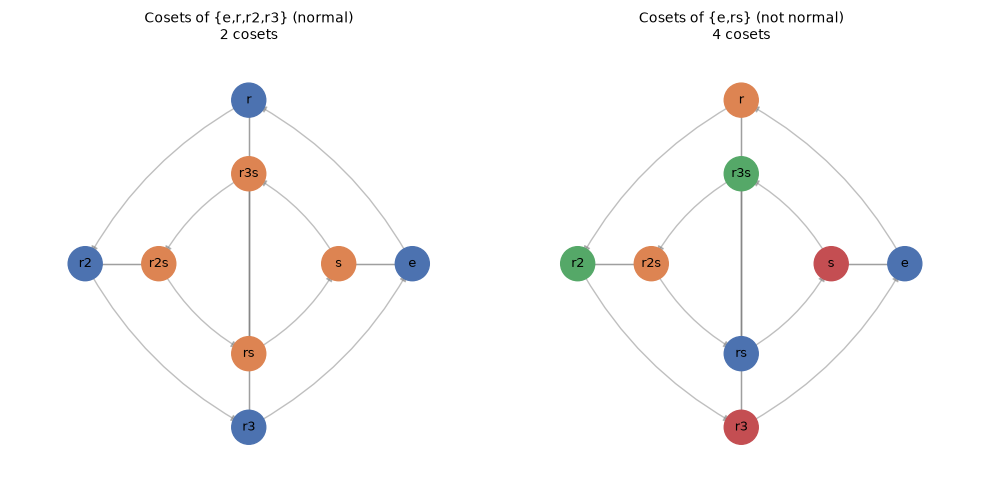

In [4]:
G = nx.MultiDiGraph()
G.add_nodes_from(names)
for e in elts:
    G.add_edge(name_of[e], name_of[compose(e, r)], gen="r")
    G.add_edge(name_of[e], name_of[compose(e, s)], gen="s")

def orbit(start):
    order, cur = [start], start
    for _ in range(3):
        cur = compose(cur, r)
        order.append(cur)
    return order

pos = {}
for i, e in enumerate(orbit((0, 0))):
    ang = 2 * np.pi * i / 4
    pos[name_of[e]] = (np.cos(ang), np.sin(ang))
for i, e in enumerate(orbit((0, 1))):
    ang = 2 * np.pi * i / 4
    pos[name_of[e]] = (0.55 * np.cos(ang), 0.55 * np.sin(ang))

def coset_colors(H, palette):
    cosets, color_of = {}, {}
    for g in elts:
        c = left_coset(g, H)
        if c not in cosets:
            cosets[c] = palette[len(cosets) % len(palette)]
        color_of[name_of[g]] = cosets[c]
    return color_of

palette = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]
color_rot = coset_colors(H_rotations, palette)
color_ref = coset_colors(H_reflection, palette)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
titles = ["Cosets of {e,r,r2,r3} (normal)\n2 cosets", "Cosets of {e,rs} (not normal)\n4 cosets"]
for ax, colors, title in zip(axes, [color_rot, color_ref], titles):
    node_colors = [colors[n] for n in G.nodes()]
    edge_r = [(u, v) for u, v, d in G.edges(data=True) if d["gen"] == "r"]
    edge_s = [(u, v) for u, v, d in G.edges(data=True) if d["gen"] == "s"]
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, ax=ax, node_size=600)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=9)
    nx.draw_networkx_edges(G, pos, edgelist=edge_r, edge_color="gray", ax=ax,
                            connectionstyle="arc3,rad=0.15", arrows=True, arrowsize=10, alpha=0.5)
    nx.draw_networkx_edges(G, pos, edgelist=edge_s, edge_color="gray", ax=ax,
                            arrows=False, width=1.0, alpha=0.5)
    ax.set_title(title, fontsize=10)
    ax.axis("equal"); ax.axis("off")
fig.tight_layout()
plt.show()


**Try it:** the rotation subgroup has index 2 (2 cosets), and index-2
subgroups are *always* normal, in any group — can you sketch why, using only
the fact that a left coset and its matching right coset both have to be
"everything except $H$" when there are only two cosets total?


---
# 4. Well-definedness, caught in the act

The whole point of normality: we want to define multiplication *on cosets*
by $(gH)(hH) := (gh)H$ — but this only makes sense if the answer doesn't
depend on *which* representatives $g$ and $h$ you picked from their cosets.
Let's test it directly: take two different elements of the *same* coset,
multiply both by the same thing, and see if the results still land in the
same coset.


In [5]:
# H_rotations (normal): e and r2 are both in the "rotations" coset.
rep_a, rep_b = name_to_elt["e"], name_to_elt["r2"]
gen = name_to_elt["s"]
coset_a = left_coset(compose(rep_a, gen), H_rotations)
coset_b = left_coset(compose(rep_b, gen), H_rotations)
print("H_rotations: e*s lands in", sorted(name_of[x] for x in coset_a))
print("H_rotations: r2*s lands in", sorted(name_of[x] for x in coset_b))
print("Same coset both times ->", coset_a == coset_b, "(multiplication on cosets is well-defined)\n")

# H_reflection (not normal): r and its partner share the same left coset.
coset_of_r = left_coset(name_to_elt["r"], H_reflection)
rep_c = name_to_elt["r"]
rep_d = next(x for x in coset_of_r if x != rep_c)
print(f"r and {name_of[rep_d]} share a coset:", sorted(name_of[x] for x in coset_of_r))
gen2 = name_to_elt["r"]
coset_c = left_coset(compose(rep_c, gen2), H_reflection)
coset_d = left_coset(compose(rep_d, gen2), H_reflection)
print("H_reflection: r*r  lands in", sorted(name_of[x] for x in coset_c))
print(f"H_reflection: {name_of[rep_d]}*r lands in", sorted(name_of[x] for x in coset_d))
print("Same coset both times ->", coset_c == coset_d, "(if False, 'multiplication on cosets' isn't even a function!)")


H_rotations: e*s lands in ['r2s', 'r3s', 'rs', 's']
H_rotations: r2*s lands in ['r2s', 'r3s', 'rs', 's']
Same coset both times -> True (multiplication on cosets is well-defined)

r and r2s share a coset: ['r', 'r2s']
H_reflection: r*r  lands in ['r2', 'r3s']
H_reflection: r2s*r lands in ['e', 'rs']
Same coset both times -> False (if False, 'multiplication on cosets' isn't even a function!)


That second `False` is the whole reason quotients require normal subgroups:
$gH \cdot hH$ isn't a well-defined operation at all when $H$ isn't normal —
you'd get a different answer depending on which representative you happened
to pick, which isn't a group operation, it's not even a function.


---
# 5. Summary

- Cosets always partition a group into equal-size pieces — that's just
  Lagrange's theorem, and it costs nothing.
- **Normal** means left cosets equal right cosets for every element.
  Equivalently (and this is what actually gets used): $gHg^{-1} = H$ for
  every $g$.
- The payoff for normality is that $(gH)(hH) := (gh)H$ becomes a genuine,
  well-defined group operation on the set of cosets — the quotient group
  $G/H$. Without normality, that formula isn't even a function, as Section 4
  demonstrated directly rather than just asserted.
- Every index-2 subgroup is automatically normal (Section 3's exercise) —
  which is why $D_4$'s rotation subgroup, and the alternating group $A_n$
  inside $S_n$, are normal for a reason that has nothing to do with those
  specific groups.


---
# 6. Exercises

1. **Build the quotient.** $D_4 / \{e,r,r^2,r^3\}$ has exactly 2 elements.
   Write out its multiplication table directly (you already have both
   cosets from Section 2) and check it matches $\mathbb{Z}_2$.
2. **A second non-normal example.** Repeat Section 2's check with
   `H = {e, r3s}` (a different reflection). Confirm it's also not normal,
   and find a `g` for which left and right cosets differ.
3. **A normal subgroup that is not the rotations.** The four elements
   `{e, r2, rs, r3s}` form a subgroup of index 2. Check that it is closed,
   confirm with `show_cosets` that it is normal (as the Section 3 exercise
   predicts), and identify the 2-element quotient. Does it matter that this
   subgroup contains reflections?
4. **Cosets of $\mathbb{Z}_8$.** Cyclic groups are abelian, so left and right
   cosets always agree trivially. Compute the cosets of `{0, 4}` inside
   $\mathbb{Z}_8$ and describe the quotient group you get.


---
## License

This notebook is released under the [Creative Commons Attribution 4.0
International License (CC BY 4.0)](https://creativecommons.org/licenses/by/4.0/). You are free to copy, adapt,
and redistribute it, including for commercial purposes, provided you give
appropriate credit.

Suggested attribution: *"Cosets, Normality, and Quotient Groups" by [Eduardo Dueñez](https://supernumero.us/about),
licensed under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).*
